# Extended global-discrimination benchmarks

This notebook evaluates **Greedy**, **Near-uniform**, and **Random** allocation
on the extended 1D and 2D benchmarks with $K=3,\ldots,7$ and
$M=3,\ldots,8$. It reports actual equal-prior PGM error from the output-state
Gram matrix. Exhaustive Optimal is intentionally reserved for the compact
benchmark, where it provides a tractable exact reference.

In [4]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
from IPython.display import display

NOTEBOOK_DIRECTORY = Path.cwd().resolve()
if not (NOTEBOOK_DIRECTORY / "comparison_analysis.py").exists():
    NOTEBOOK_DIRECTORY = NOTEBOOK_DIRECTORY / "min-error-global"
if str(NOTEBOOK_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIRECTORY))

import comparison_analysis
comparison_analysis = importlib.reload(comparison_analysis)

load_paired_results = comparison_analysis.load_paired_results
format_global_results_summary = comparison_analysis.format_global_results_summary
make_extended_comparison_plots = comparison_analysis.make_extended_comparison_plots
phase_range_summary = comparison_analysis.phase_range_summary
run_scalable_dataset = comparison_analysis.run_scalable_dataset

## Run settings

`RUN_ALL_CASES = False` selects a reproducible 100-case stratified sample from
each extended dataset. `RUN_ALL_CASES = True` evaluates all 2,700 cases per
dimension. Both modes evaluate all three input states and $N=3,\ldots,12$.
The extended runner excludes exhaustive Optimal by design.

In [5]:
DATASETS = ("benchmark_1d", "benchmark_2d")
RUN_ALL_CASES = True
TEST_CASES_PER_DATASET = 100
SENSOR_BUDGETS = tuple(range(3, 13))
SAMPLE_SEED = 20260827
RESULTS_ROOT = (
    NOTEBOOK_DIRECTORY
    / "results"
    / "actual_pgm_scalable_methods_c_pi_extended"
)

RUN_MODE = "full" if RUN_ALL_CASES else "test"
print("Run mode:", RUN_MODE)
print("Sensor budgets:", SENSOR_BUDGETS)
print("Results directory:", RESULTS_ROOT)

Run mode: full
Sensor budgets: (3, 4, 5, 6, 7, 8, 9, 10, 11, 12)
Results directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-global/results/actual_pgm_scalable_methods_c_pi_extended


## Evaluate scalable allocations

The same deterministic case-and-budget seeds are reused across input states for
the randomized baselines. Results are saved independently from the compact
optimality experiment.

In [6]:
records = []
for dataset in DATASETS:
    dataset_records = run_scalable_dataset(
        dataset,
        sensor_budgets=SENSOR_BUDGETS,
        run_mode=RUN_MODE,
        test_case_count=TEST_CASES_PER_DATASET,
        sample_seed=SAMPLE_SEED,
        progress_every=10,
        results_root=RESULTS_ROOT,
    )
    records.extend(dataset_records)

print(f"Completed {len(records):,} scalable state/budget runs.")

benchmark_1d: completed 10/2700 cases
benchmark_1d: completed 20/2700 cases
benchmark_1d: completed 30/2700 cases
benchmark_1d: completed 40/2700 cases
benchmark_1d: completed 50/2700 cases
benchmark_1d: completed 60/2700 cases
benchmark_1d: completed 70/2700 cases
benchmark_1d: completed 80/2700 cases
benchmark_1d: completed 90/2700 cases
benchmark_1d: completed 100/2700 cases
benchmark_1d: completed 110/2700 cases
benchmark_1d: completed 120/2700 cases
benchmark_1d: completed 130/2700 cases
benchmark_1d: completed 140/2700 cases
benchmark_1d: completed 150/2700 cases
benchmark_1d: completed 160/2700 cases
benchmark_1d: completed 170/2700 cases
benchmark_1d: completed 180/2700 cases
benchmark_1d: completed 190/2700 cases
benchmark_1d: completed 200/2700 cases
benchmark_1d: completed 210/2700 cases
benchmark_1d: completed 220/2700 cases
benchmark_1d: completed 230/2700 cases
benchmark_1d: completed 240/2700 cases
benchmark_1d: completed 250/2700 cases
benchmark_1d: completed 260/2700 c

## Extended-benchmark figures

Three figures are generated: mean actual PGM errors, field-family error
distributions, and raw runtime distributions for the three scalable methods.
The first two use six state-by-dimension panels; runtime uses 1D and 2D panels.

Extended-benchmark mean actual PGM errors


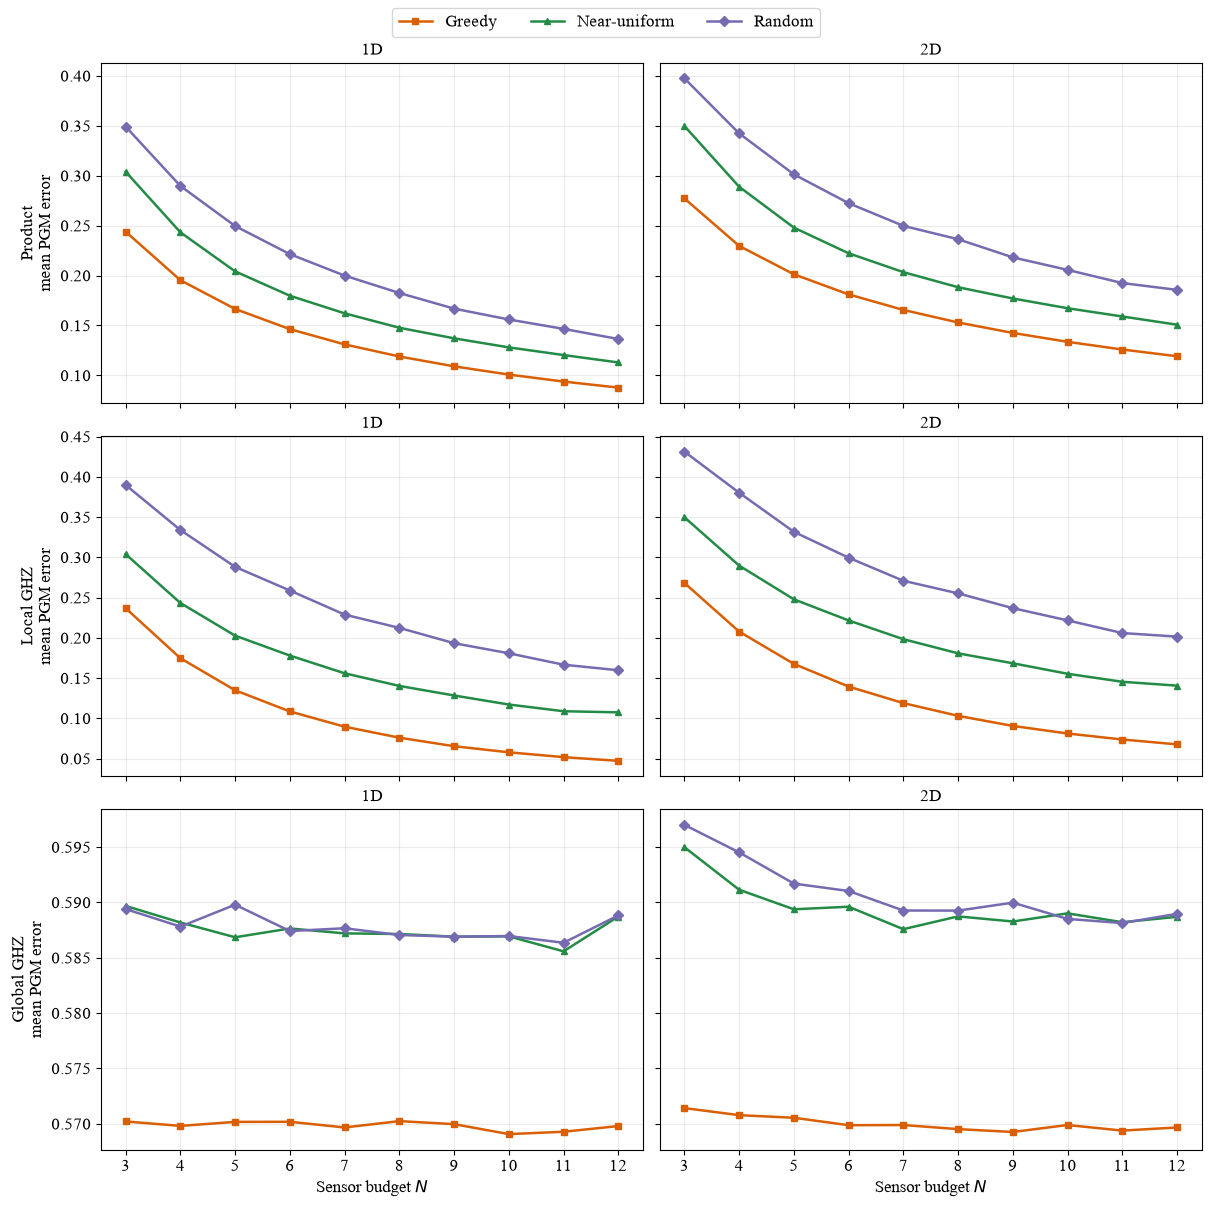

Extended-benchmark PGM error by field family


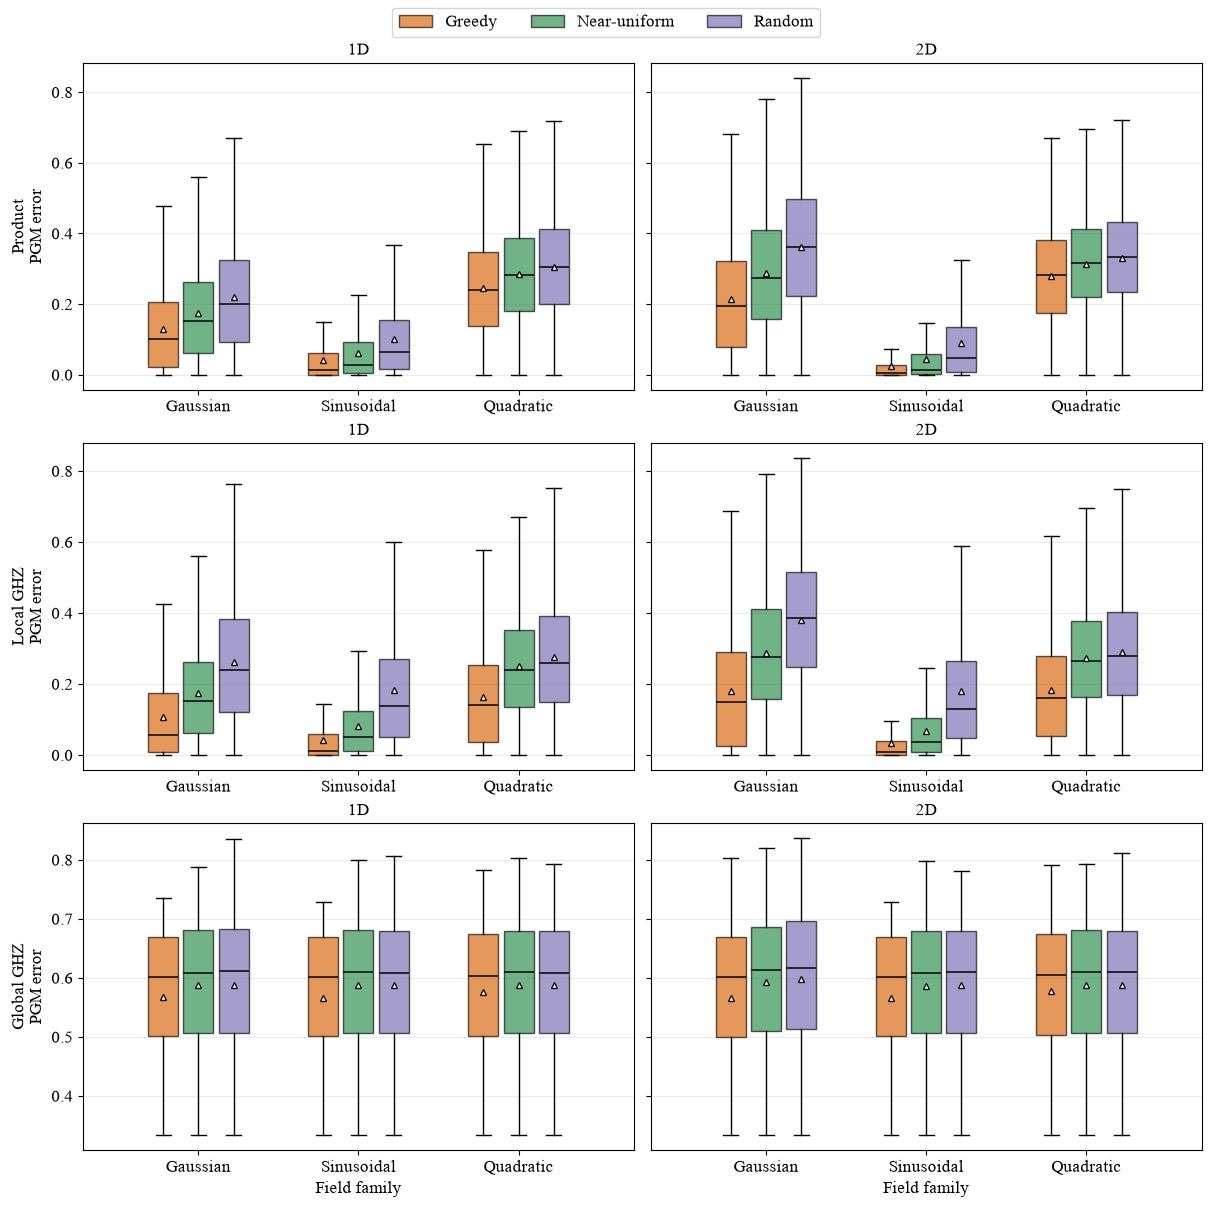

Extended-benchmark runtimes


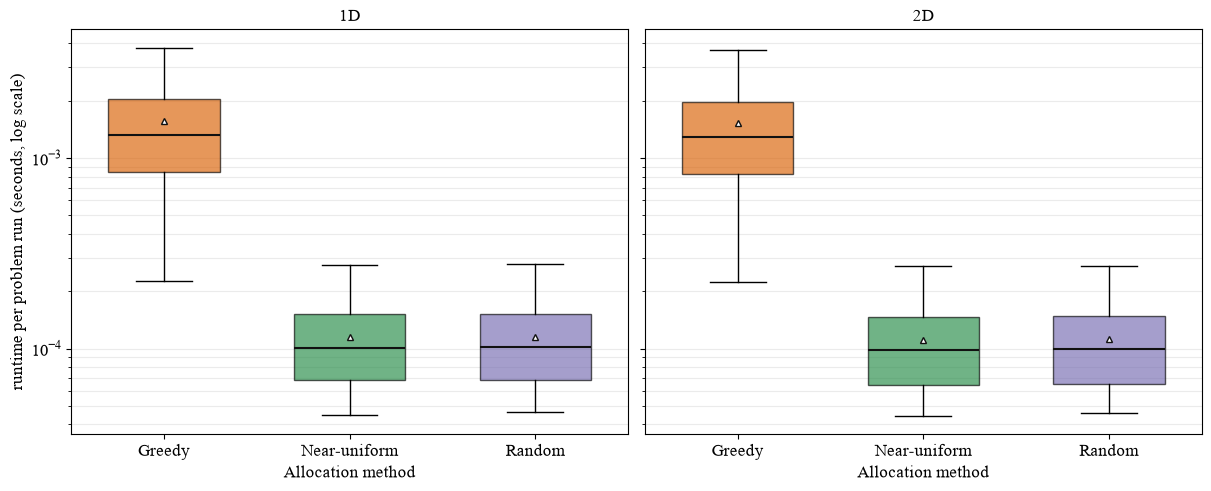

In [7]:
comparison_analysis = importlib.reload(comparison_analysis)
load_paired_results = comparison_analysis.load_paired_results
make_extended_comparison_plots = comparison_analysis.make_extended_comparison_plots

if not records:
    for dataset in DATASETS:
        records.extend(load_paired_results(dataset, results_root=RESULTS_ROOT))

FIGURE_DIRECTORY = RESULTS_ROOT / "figures"
figures = make_extended_comparison_plots(
    records,
    output_directory=FIGURE_DIRECTORY,
)
for title, figure in figures:
    print(title)
    display(figure)
    plt.close(figure)

## End-of-run numerical summary

This prints the extended baseline-reduction, sensor-budget, and
field-family statistics, followed by the phase-range diagnostic.

In [ ]:
comparison_analysis = importlib.reload(comparison_analysis)
format_global_results_summary = comparison_analysis.format_global_results_summary
print(format_global_results_summary(records, compact=False))

phase_ranges = comparison_analysis.phase_range_summary(records)
print("\nObserved phase ranges")
for name, value in phase_ranges.items():
    print(f"{name}: {value}")
print("Saved figures:", FIGURE_DIRECTORY)

## Paper figure recommendation

Use a **three-figure core result** in the main paper:

1. From `comapre.ipynb`, include `mean_actual_pgm_error_gaps` to show how close
   Greedy, Near-uniform, and Random are to exact Optimal on the compact design.
2. From this notebook, include `extended_mean_actual_pgm_errors` to show how the
   scalable methods behave across the larger $K$ and $M$ ranges.
3. From `comapre.ipynb`, include `pgm_error_gap_by_field_family` to report
   Gaussian, sinusoidal, and quadratic sensitivity against exact Optimal.

Include `runtime_boxplots` from the compact experiment as a third main figure
only when computational speedup is a central claim. Otherwise place both the
compact speedup plot, `extended_pgm_error_by_field_family`, and
`extended_runtime_boxplots` in supplementary material.

The separate Greedy and Optimal input-state comparison figures are redundant
with the six-panel figures and should not consume main-paper space.